<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
## Task 1: Setup and Compute Entropy of Observed Weather Distribution

First, let's set up the simulated weather distribution for 30 days and calculate its Shannon entropy.

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Observed weather frequencies over 30 days (e.g., 15 Sunny, 9 Cloudy, 6 Rainy)
observed_counts = np.array([15, 9, 6])
P = observed_counts / np.sum(observed_counts)

# Compute Entropy H(P)
entropy_P = stats.entropy(P, base=2)

print(f"Observed probabilities (P): Sunny={P[0]:.3f}, Cloudy={P[1]:.3f}, Rainy={P[2]:.3f}")
print(f"Entropy H(P): {entropy_P:.4f} bits")

Observed probabilities (P): Sunny=0.500, Cloudy=0.300, Rainy=0.200
Entropy H(P): 1.4855 bits


```markdown
## Task 2 & 3: Compute Cross-Entropy, KL Divergence, and Verify the Relationship

We define predictions from Model Q1 and Model Q2, compute Cross-Entropy and KL Divergence against P, and verify that $H(P, Q) = H(P) + D_{KL}(P \parallel Q)$.

In [2]:
# Two competing models
Q1 = np.array([0.6, 0.3, 0.1]) # Closer to P
Q2 = np.array([0.3, 0.4, 0.3]) # Further from P

def cross_entropy(p, q):
    # H(P, Q) = -sum(p * log2(q))
    return -np.sum(p * np.log2(q))

# Compute metrics for Model Q1
ce_q1 = cross_entropy(P, Q1)
kl_q1 = stats.entropy(P, Q1, base=2)

# Compute metrics for Model Q2
ce_q2 = cross_entropy(P, Q2)
kl_q2 = stats.entropy(P, Q2, base=2)

print("--- Model Q1 Performance ---")
print(f"Cross-Entropy H(P, Q1): {ce_q1:.4f} bits")
print(f"KL Divergence D_KL(P || Q1): {kl_q1:.4f} bits")
print(f"Verification [H(P) + D_KL]: {entropy_P + kl_q1:.4f} bits (Matches Cross-Entropy: {np.isclose(ce_q1, entropy_P + kl_q1)})")

print("\n--- Model Q2 Performance ---")
print(f"Cross-Entropy H(P, Q2): {ce_q2:.4f} bits")
print(f"KL Divergence D_KL(P || Q2): {kl_q2:.4f} bits")
print(f"Verification [H(P) + D_KL]: {entropy_P + kl_q2:.4f} bits (Matches Cross-Entropy: {np.isclose(ce_q2, entropy_P + kl_q2)})")

--- Model Q1 Performance ---
Cross-Entropy H(P, Q1): 1.5540 bits
KL Divergence D_KL(P || Q1): 0.0685 bits
Verification [H(P) + D_KL]: 1.5540 bits (Matches Cross-Entropy: True)

--- Model Q2 Performance ---
Cross-Entropy H(P, Q2): 1.6125 bits
KL Divergence D_KL(P || Q2): 0.1270 bits
Verification [H(P) + D_KL]: 1.6125 bits (Matches Cross-Entropy: True)


```markdown
## Task 4: Show that KL Divergence is Asymmetric

We show that $D_{KL}(P \parallel Q) \neq D_{KL}(Q \parallel P)$.

In [4]:
kl_P_Q1 = stats.entropy(P, Q1, base=2)
kl_Q1_P = stats.entropy(Q1, P, base=2)

print(f"D_KL(P || Q1): {kl_P_Q1:.4f} bits")
print(f"D_KL(Q1 || P): {kl_Q1_P:.4f} bits")
print(f"Are they equal? {np.isclose(kl_P_Q1, kl_Q1_P)}")

D_KL(P || Q1): 0.0685 bits
D_KL(Q1 || P): 0.0578 bits
Are they equal? False


```markdown
## Task 5: Plot Binary Cross-Entropy Loss

Let's plot binary cross-entropy loss against predicted probability for target values $y = 1$ and $y = 0$.

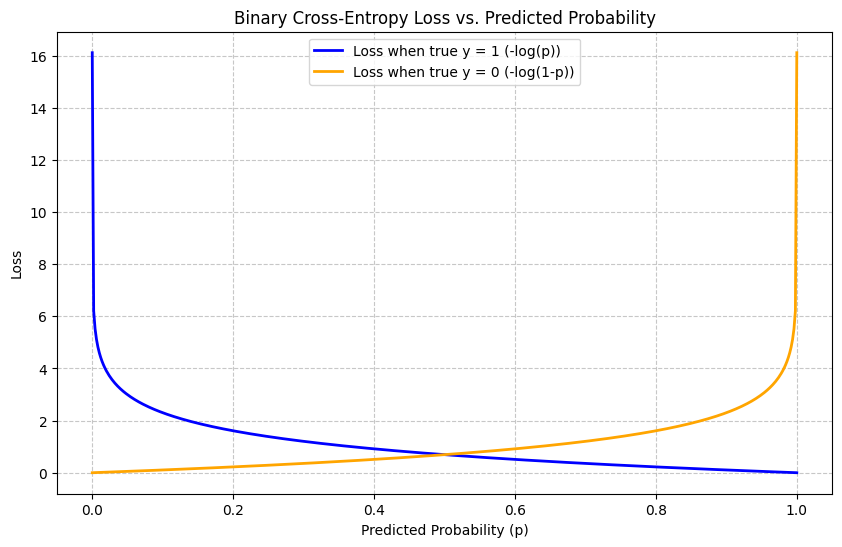

In [3]:
epsilon = 1e-7
epsilon_prob = np.linspace(epsilon, 1 - epsilon, 500)

loss_y_1 = -np.log(epsilon_prob)
loss_y_0 = -np.log(1 - epsilon_prob)

plt.figure(figsize=(10, 6))
plt.plot(epsilon_prob, loss_y_1, label='Loss when true y = 1 (-log(p))', color='blue', lw=2)
plt.plot(epsilon_prob, loss_y_0, label='Loss when true y = 0 (-log(1-p))', color='orange', lw=2)
plt.title('Binary Cross-Entropy Loss vs. Predicted Probability')
plt.xlabel('Predicted Probability (p)')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()